# Spatial Regression with Partial Differential Equation Regularization

fdaPDE Team, MOX, Department of Mathematics, Politecnico di Milano, Italy

`fdaPDE` (Palummo et al., 2025) is a C++ library with an interface to R for *physics-informed spatial and functional data analysis*, at the intersection of statistics and numerical analysis. The library provides advanced statistical methods designed for data located over complex spatial domains, ranging from irregular planar regions and curved surfaces to linear networks and volumes, possibly evolving over time. The class of methods implemented in `fdaPDE` features regularization terms based on Partial Differential Equations (PDEs), which allow incorporating information derived from the physics of the problem under study into the statistical modeling. This makes `fdaPDE` an extremely flexible tool for the analysis of complex data. For a review of this class of methods, refer to @sangalli2021spatial.

`fdaPDE` offers a wide range of modeling capabilities -- including regression, nonparametric
density estimation, functional data analysis, and more -- for data located over a spatial domain,
possibly evolving over time. Among the broad range of modeling capabilities offered by `fdaPDE`, we focus here on the **spatial regression method**.

## Model

Let $\mathcal{D} \subset \mathbb{R}^d\,,$ with $d \geq 1\,,$ be a bounded *spatial domain* of interest in which $n$ fixed *measurement stations* are located. Here, we consider $d = 2\,,$ but the proposed method can handle multidimensional spatial domains with complex shapes, including *two-dimensional curved surfaces* [@ettinger2016spatial] and *non-convex three-dimensional volumes* [@arnone2023analyzing]. At the location $\mathbf{p}_i =(p_{1i}, p_{2i})^\top \in \mathcal{D}$ of each measurement station, we observe a realization $y_i \in \mathbb{R}$ of the response variable $Y_i$ under study, along with a set of covariates $\mathbf{x}_i = \left( x_{i,1},\ldots,x_{i,q} \right)^\top \in \mathbb{R}^q\,,$ if available. We present a **semiparametric spatial regression model** with Partial Differential Equation (PDE) regularization, which we formulate as follows:
$$y_i = \mathbf{x}_i^\top \boldsymbol{\beta} + f(\mathbf{p}_i) + \varepsilon_i\,, \qquad i = 1, \ldots, n\,,$$
where:
  
- $\boldsymbol{\beta} \in \mathbb{R}^q$ is the vector of **unknown regression coefficients** capturing the mean effects of the covariates;

- $f(\mathbf{p}_i) \in \mathbb{R}$ is the **unknown deterministic spatial field** $f : \mathcal{D} \to \mathbb{R}$ at the $i$th data location;

- $\varepsilon_i \in \mathbb{R}$ is the **measurement error**; in particular, errors in $\boldsymbol{\varepsilon} = \left( \varepsilon_1, \ldots, \varepsilon_n \right)^\top \in \mathbb{R}^n$ are assumed to be independent and identically distributed, having *zero mean* and *finite variance* $\sigma^2\,.$
  
To estimate the unknown parameters, we refer to the basic form of the regularized methods, as reviewed in @sangalli2021spatial and originally introduced in @sangalli2013spatial. These works propose to minimize the following penalized functional based on the sum of squared errors:
$$\frac{1}{n} \sum_{i = 1}^n \left( y_i - \mathbf{x}_i^\top \boldsymbol{\beta} - f(\mathbf{p}_i) \right)^2 + R(f; \lambda)\,,$$
where $R(f; \lambda)$ is the **regularization term** that depends on the **smoothing parameter** $\lambda \in \mathbb{R}^+\,.$ The regularization term is defined using PDEs, with differential operators encoding the smoothness of $f$ over $\mathcal{D}\,.$ This term may also incorporate problem-specific information into the modeling framework, whenever available. The functional above embodies the trade-off between *data fidelity* and *model fidelity* through the least-squares term and the misfit with respect to the PDE, respectively. The balance between these two contributions is governed by the smoothing parameter $\lambda\,.$

The regularization term is given by:
$$R(f; \lambda) = \lambda \int_\mathcal{D} \left( L f - u \right)^2 \, \text{d}\mathbf{p}\,,$$
where $Lf = u$ is the PDE modeling the spatial variation of the unknown spatial field $f$ over $\mathcal{D}\,.$ The PDE encodes problem-specific information derived from the physics of the phenomenon under study and formalizes it in terms of $f\,.$ In the most general case, the method currently supports **second-order linear elliptic PDEs**, with **diffusion-transport-reaction operators** of the following form:
$$Lf = -\nabla \cdot (K \nabla f) + \mathbf{b} \cdot \nabla f + cf\,,$$
where:
  
- the symmetric and positive definite matrix $K \in \mathbb{R}^{2\times2}$ is the **diffusion tensor**, which models potential anisotropy;

- $\mathbf{b} \in \mathbb{R}^2$ is the **transport vector**, which generates one-directional smoothing;

- $c \in \mathbb{R}^+$ is the **reaction coefficient**, which is responsible for shrinking the field $f$ to zero.

Each of these parameters, along with the **forcing term** $u \in L^2(\mathcal{D})\,,$ can vary over space and contribute to modeling different forms of anisotropy and non-stationarity. Consistent with the application presented in this vignette, we will focus on homogeneous forcing terms $u \equiv 0\,.$ For non-homogeneous forcing terms, refer to @azzimonti2014mixed, @azzimonti2015blood, and @arnone2019modeling. If prior knowledge about the phenomenon under study is not available, the regularization term leads to *stationary and isotropic smoothing* through the Laplace operator $\Delta\,,$ corresponding to $K = I\,,$ $\mathbf{b} = \mathbf{0}\,,$ and $c = 0\,.$ Moreover, problem-specific conditions on $f$ may be imposed at the boundary $\partial\mathcal{D}$ of the spatial domain. The method currently supports Dirichlet, Neumann, and Robin boundary conditions, which respectively set the value of $f$ at $\partial\mathcal{D}\,,$ its normal derivative at $\partial\mathcal{D}\,,$ or a combination of both. In addition, boundary conditions may vary over $\partial\mathcal{D}\,.$
  
The method for Spatial Regression with Partial Differential Equation regularization presented in this vignette, hereafter referred to as `SR-PDE`, is implemented within the newest version of the `fdaPDE` C++ library (Palummo et al., 2025). We load the library in the working environment as follows:

In [1]:
# Google Colab setup. Skip this cell when running locally.
if (any(nzchar(Sys.getenv(c(
  "COLAB_RELEASE_TAG",
  "COLAB_BACKEND_VERSION"
))))) {

  # Download the repository.
  repository <- "/content/course-materials"

  if (!dir.exists(repository)) {
    stopifnot(system2(
      "git",
      c(
        "clone", "--depth", "1",
        "https://github.com/fdaPDE/course-materials.git",
        shQuote(repository)
      )
    ) == 0L)
  }

  # Set the working directory and configure dependencies.
  setwd(file.path(
    repository,
    "courses",
    "[2026-Lancaster]-Physics-Informed-Statistical-Learning-for-Spatial-and-Functional-Data",
    "R", "notebook"
  ))

  source("../utils/colab_setup.R")
}

In [2]:
rm(list = ls())

# Import the fdaPDE library
# Load additional libraries and helper functions for plotting
suppressPackageStartupMessages({
    library(fdaPDE2)
    source("../utils/graphics.R")
  })

In [3]:
theme_set(theme_minimal() +
  theme(
    axis.title = element_text(),
    axis.text = element_text(),
    axis.ticks = element_line(),
    panel.grid = element_line()
  )
)

## Application to oceanographic quantities around the Florida peninsula

As a benchmark application in environmental sciences, we consider *oceanographic data* in the Gulf of Mexico, around the Florida peninsula. @tomasetto2024modeling presents this application in the context of spatial regression with differential regularization, proposing a *parameter cascading* approach for the estimation of PDE parameters, building on a first investigation by @bernardi2018modeling. The dataset contains some indicators of water quality measured at 30 moored buoys, serving as monitoring stations, on April 1, 2020. In particular, we consider the **Sea Surface Temperature** (SST) and **Dissolved Oxygen** (DO) at standard depth levels. The dataset is freely and publicly available by different data sources, including the [National Data Buoy Center](https://www.ndbc.noaa.gov/) and the [National Centers for Environmental Information](https://www.ncei.noaa.gov/archive/accession/NCEI-WOA18) of the National Oceanic and Atmospheric Administration (NOAA). SST is vital for marine ecosystems, weather prediction, and climate monitoring, influencing biological activity, atmospheric circulation, and heat absorption from climate change. On the other hand, DO is a key indicator of aquatic ecosystem health, essential for marine life and water quality. Monitoring its spatial distribution aids in the early detection and mitigation of environmental issues.

### 1. Spatial domain

First, we load the geometry of the **spatial domain** under study, created by preprocessing the Florida administrative boundary. This stage includes defining the specific region of interest located in the Gulf of Mexico, removing minor islands, and reducing the resolution of the coastlines. We imported the Florida administrative boundary using the `tigris` [@walker2025tigris] R package, and performed subsequent preprocessing steps relying on the `sf` [@pebesma2025sf] and `rmapshaper` [@teucher2025rmapshaper] R packages.

The preprocessed geometry of the spatial domain is available from the file `../../data/SRPDE_2D/domain.shp` and can be loaded through `sf` as follows.

In [4]:
## [SPATIAL DOMAIN]
# Load domain
domain <- st_read(dsn = "../../data/SRPDE_2D/domain.shp", quiet = TRUE)
domain

NAME,geometry
<chr>,<POLYGON [°]>
Gulf of Mexico,"POLYGON ((-78.975 30.655, -..."


The spatial domain can be interactively visualized using the `mapview` [@appelhans2025mapview] R package.

In [5]:
# Interactive plot
display_map(
    mapview(domain,
        col.regions = "gray25", alpha.regions = 0.25, col = "black", lwd = 1.5,
        legend = FALSE, layer.name = "domain")
)

<iframe srcdoc="<!doctype html>
<html>
	<head>
 <meta charset="utf-8">
 <script title="htmlwidgets" src="..."></script>
<script title="jquery" src="..."></script>
<script title="leaflet" src="..."></script>
<link href="

<div style="text-align: center;">
Figure 1: Spatial domain of interest -- a portion of the Gulf of Mexico around the Florida peninsula.
</div>
  
Now we build a **regular mesh** of the spatial domain under consideration. We create a mesh based on boundary nodes and segments, and then we refine it by setting the maximum element area to 0.01 and the minimum angle to 20 degrees. To obtain the boundary nodes, we rely on the `sf` functionality, while the triangulation is constructed using the `RTriangle` [@shewchuk2025RTriangle] R package. Other software can be used to get the triangulation; for example, it can be constructed through the `fmesher` [@lindgren2025fmesher] R package.

In [6]:
## [MESH]
# Define boundary nodes
boundary_nodes <- st_cast(x = domain, "POINT", crs = 4326)
boundary_nodes <- st_coordinates(x = boundary_nodes)
boundary_nodes <- data.frame(lon = boundary_nodes[,1], lat = boundary_nodes[,2])

# Remove the last node (duplicate node)
boundary_nodes <- boundary_nodes[-nrow(boundary_nodes),]

# Define boundary segments
boundary_segments <- cbind(1:nrow(boundary_nodes), c(2:nrow(boundary_nodes), 1))

# Create a planar straight line graph object
boundary_pslg <- pslg(P = boundary_nodes, S = boundary_segments)

# Create a regular mesh of the spatial domain
mesh_regular <- triangulate(p = boundary_pslg)
if (is.null(mesh_regular$H)) mesh_regular$H <- matrix(data = numeric(0), ncol = 2)

# Refine the mesh of the spatial domain
mesh_regular <- triangulate(p = mesh_regular, a = 0.01, q = 20, D = TRUE)
if (is.null(mesh_regular$H)) mesh_regular$H <- matrix(data = numeric(0), ncol = 2)

# Number of nodes
cat("Number of nodes:", nrow(mesh_regular$P), "\n")

# Number of triangles
cat("Number of triangles:", nrow(mesh_regular$T))

Warning message in st_cast.sf(x = domain, "POINT", crs = 4326):
“repeating attributes for all sub-geometries for which they may not be constant”


Number of nodes: 2851 
Number of triangles: 5342

We convert the `triangulation` object from `RTriangle` so that it can be read by `fdaPDE`.

In [7]:
# Set up the triangulation for fdaPDE
mesh <- triangulation(nodes = mesh_regular$P, cells = mesh_regular$T, boundary = mesh_regular$PB)

In [8]:
# Nodes coordinates
head(mesh$nodes)

# Number of nodes
cat("Number of nodes:", mesh$n_nodes)

-78.97500,30.65500
-78.97500,23.30500
-85.27500,23.30500
-85.27500,29.69238
-85.12147,29.71585
-84.88178,29.73388


Number of nodes: 2851

In [9]:
# Edges
head(mesh$edges)

# Number of edges
cat("Number of edges:", mesh$n_edges)

37,284
37,365
284,365
731,1044
1044,1047
731,1047


Number of edges: 8192

In [10]:
# Triangles
head(mesh$cells)

# Number of triangles
cat("Number of triangles:", mesh$n_cells)

37,284,365
1044,731,1047
172,135,170
162,240,242
42,41,43
155,177,154


Number of triangles: 5342

We visualize the resulting mesh of the spatial domain of interest.

In [11]:
# Interactive plot
display_map(
    mapview(domain,
      col.regions = "gray25", alpha.regions = 0.25, col = "black", lwd = 1.5,
      legend = FALSE, layer = "domain") +
    mapview(mesh, 
      crs = 4326, col.regions = "transparent", lwd = 1.25, 
      legend = FALSE, layer = "mesh")
)

<iframe srcdoc="<!doctype html>
<html>
	<head>
 <meta charset="utf-8">
 <script title="htmlwidgets" src="..."></script>
<script title="jquery" src="..."></script>
<script title="leaflet" src="..."></script>
<link href="

<div style="text-align: center;">
Figure 2: Regular mesh of the spatial domain of interest around the Florida peninsula with $2\,851$ nodes and $5\,342$ triangles.
</div>

We use the triangulation just created to define the spatial support of a `geoframe` object. This object will host layers containing data observed over the spatial support.

In [12]:
# Create the geoframe
florida <- geoframe(domain = mesh)
florida

Geoframe with 0 layers
Bounding box:    xmin: -85.275 ymin: 23.305 xmax: -78.975 ymax: 30.655
Number of nodes: 2851
Number of cells: 5342


### 2. Data

We import the preprocessed data from the file `../../data/SRPDE_2D/data.txt` as a `data.frame` object. We add a data layer to the `geoframe` object defined above, thus obtaining a format compatible with the implementation of the proposed regression method.

In [13]:
## [DATA]
# Load the data
data <- read.table(file = "../../data/SRPDE_2D/data.txt", header = TRUE)

# Add layer with data to the geoframe object
florida$insert(layer = "ocean", type = "point", geo = c("lon", "lat"), data = data)
florida

Geoframe with 1 layers
Bounding box:    xmin: -85.275 ymin: 23.305 xmax: -78.975 ymax: 30.655
Number of nodes: 2851
Number of cells: 5342

Layer: ocean
Type:  POINT
Dims: 30, 6
First 6 data rows:
SST     DO      Nitrate  Phosphate Salinity Silicate 
<flt64> <flt64> <flt64>  <flt64>   <flt64>  <flt64>  
26.535  207.854 0.125092 0.0931902 36.0824  1.47634  
25.661  208.587 0.115277 0.107791  36.1013  1.8409   
27.383  205.318 0.125819 0.116948  36.1282  1.74541  
25.54   208.724 0.221984 0.0688162 36.3097  1.07479  
26.43   208.587 0.115277 0.107791  36.1176  1.8409   
27.037  207.854 0.125092 0.0931902 36.0895  1.47634  

The recorded values are shown in the interactive plot below.

In [14]:
# Interactive plot
display_map(
    mapview(florida[["ocean"]], 
      crs = 4326,
      color_palettes = list("inferno", "viridis", "viridis", "viridis", "viridis", "viridis"))
)

<iframe srcdoc="<!doctype html>
<html>
	<head>
 <meta charset="utf-8">
 <script title="htmlwidgets" src="..."></script>
<script title="jquery" src="..."></script>
<script title="leaflet" src="..."></script>
<link href="

<div style="text-align: center;">
Figure 3: Sea Surface Temperature (SST), Dissolved Oxygen (DO), and concentrations of Nitrate, Phosphate, Salinity, and Silicate, observed at 30 monitoring stations located in the Gulf of Mexico, around the Florida peninsula, on April 1, 2020.
</div>

First, we focus on the SST. The *non-standard shape* of the spatial domain strongly influences the oceanographic quantity under study. For example, temperatures recorded at two buoys located on opposite sides of the Florida peninsula are naturally less correlated than those recorded at two buoys situated the same distance apart but on the same side of the peninsula. `SR-PDE` naturally accounts for the geometry of the domain, which features irregular boundaries and concavities.

#### 2.1 SST satellite images

In addition to the data introduced above, the file `../../data/SRPDE_2D/SST.tif` contains a `raster` [@hijmans2025raster] object with the SST values observed from high resolution satellite images provided by the Jet Propulsion Laboratory of the [National Aeronautics and Space Administration (NASA)](https://podaac.jpl.nasa.gov/dataset/MUR-JPL-L4-GLOB-v4.1).

In [15]:
# Load the SST data from NASA satellite images as a raster object
SST <- raster("../../data/SRPDE_2D/SST.tif")
SST

class      : RasterLayer 
dimensions : 735, 628, 461580  (nrow, ncol, ncell)
resolution : 0.01, 0.01  (x, y)
extent     : -85.275, -78.995, 23.305, 30.655  (xmin, xmax, ymin, ymax)
crs        : +proj=longlat +datum=WGS84 +no_defs 
source     : SST.tif 
names      : SST 
values     : 293.588, 301.339  (min, max)


The SST data from NASA satellite images appear as follows:

<iframe srcdoc="<!doctype html>
<html>
	<head>
 <meta charset="utf-8">
 <script title="htmlwidgets" src="..."></script>
<script title="jquery" src="..."></script>
<script title="leaflet" src="..."></script>
<link href="
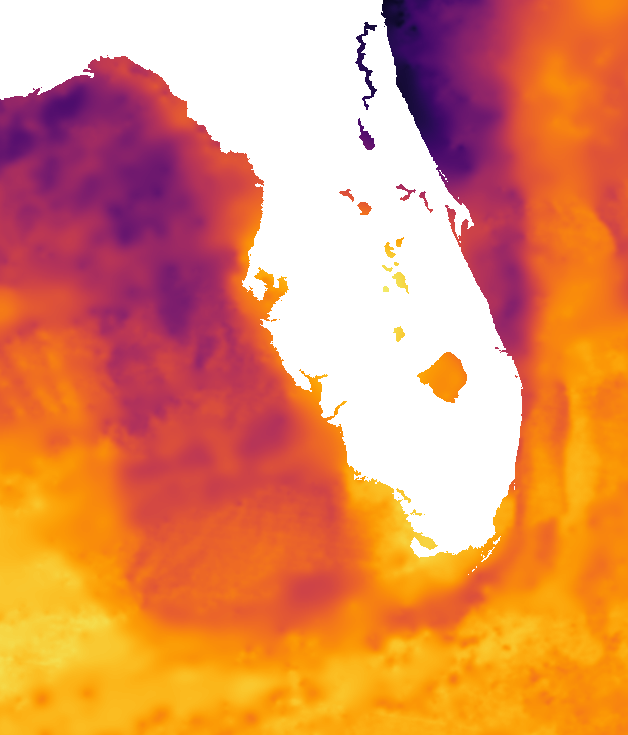

In [16]:
# Interactive plot
display_map(
    mapview(SST - 273.15, 
      col.regions = inferno, na.color = "transparent",
      layer.name = "SST [°C]") +
    mapview(domain, 
      col.regions = "transparent", alpha.regions = 0,
      col = "black", lwd = 1.5, layer.name = "domain", legend = FALSE)
)

<div style="text-align: center;">
Figure 4: SST data from NASA satellite images, used solely for comparison with the SST estimates computed by the proposed `SR-PDE` method in the next section.
</div>

We point out that these data are not used for estimation purposes; they are displayed here solely to enable comparison with respect to the SST estimate provided by the proposed `SR-PDE` method in the next section. Instead, the estimation is performed using the 30 observations measured at the moored buoys, contained in the `data` variable loaded above.

### 3. SR-PDE model fitting for isotropic smoothing (without covariates)

We are ready to perform the `SR-PDE` spatial regression method using the `sr` function. This function offers several options for solving the regression problem, including the possibility to specify covariates, PDE parameters, and boundary conditions, whenever available or required by the addressed problem. In addition, the function implements different algorithms for degrees of freedom computation and criteria for optimal smoothing parameter selection. For further information, see the documentation by typing `?sr`.

Here, in its simplest form, we apply isotropic smoothing to the SST data, hereafter referred to as `SR-PDE`$(I,\mathbf{0},0)\,.$ This means that we consider:

- a **stationary and isotropic diffusion tensor**: $K = I\,,$ where $I$ is the identity matrix;

- a **null transport vector**: $\mathbf{b}(\mathbf{p}) = \mathbf{0}\,;$

- a **null reaction coefficient**: $c = 0\,;$

- a **null forcing term**: $u \equiv 0\,.$

#### 3.1 Isotropic smoothing with fixed smoothing parameter

We can fit the model with a fixed proposed value for the smoothing parameter $\lambda\,.$ For instance, we can set it to $0.00001\,,$ and compute the estimate as follows:

In [17]:
## [ISOTROPIC SMOOTHING WITH FIXED SMOOTHING PARAMETER]
# Set up the finite element function (order 1)
f_SST_iso_fixed <- fe_function(mesh, type = "P1")

# Proposed value for the smoothing parameter
lambda_fixed <- 0.00001

# Isotropic smoothing model
model_SST_iso_fixed <- sr(formula = SST ~ f_SST_iso_fixed, data = florida)

# Isotropic smoothing fit with fixed lambda
fit_SST_iso_fixed <- model_SST_iso_fixed$fit(lambda = lambda_fixed)

We print the regression model outputs.

In [18]:
# Fitted values at mesh nodes
cat("Fitted values at mesh nodes:", head(f_SST_iso_fixed$coeff), "\n")

# Fitted values at locations
cat("Fitted values at locations:", head(model_SST_iso_fixed$fitted), "\n")

# Residuals at locations: response - fitted values
cat("Residuals\n")
SST_iso_fixed_residuals <- c(florida[["ocean"]]$SST - model_SST_iso_fixed$fitted)
summary(SST_iso_fixed_residuals)

Fitted values at mesh nodes: 24.87297 25.09173 29.04511 24.88935 24.88134 24.84066 
Fitted values at locations: 26.56576 25.65666 27.37757 25.55524 26.42243 27.01873 
Residuals


      Min.    1st Qu.     Median       Mean    3rd Qu.       Max. 
-0.0685988 -0.0077553  0.0009632  0.0000000  0.0071528  0.0509515 

To evaluate the regression model fit over a fine grid and enable interactive visualization of the estimate, we internally create a new `raster` object. We then compute the fitted values over the grid using the `$eval` method. We plot the resulting estimate with `mapview`: this is just one possibility; various other plotting options are available depending on the specific purpose.

The regression model fit over the region of interest is displayed below (left). For qualitative comparison, the SST data from NASA satellite images is also displayed (right).

<iframe srcdoc="<!doctype html>
<html>
	<head>
 <meta charset="utf-8">
 <script title="htmlwidgets" src="..."></script>
<script title="jquery" src="..."></script>
<script title="leaflet" src="..."></script>
<link href="
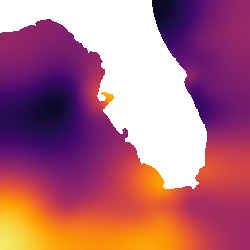
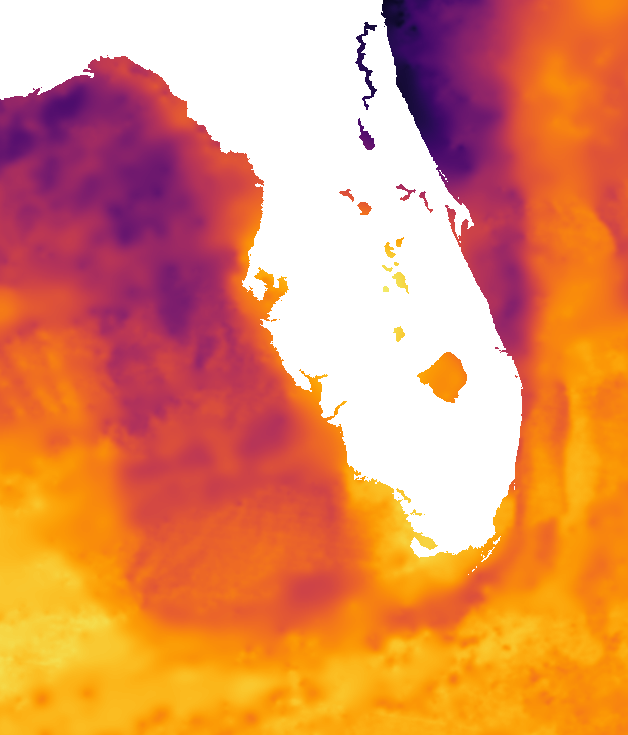

In [19]:
# Interactive plot
map1 <- mapview(f_SST_iso_fixed, 
          crs = 4326, col.regions = inferno,
          na.color = "transparent", layer.name = "SST [°C]") +
        mapview(domain, 
          col.regions = "transparent", alpha.regions = 0,
          col = "black", lwd = 1.5, layer.name = "domain", legend = FALSE)

map2 <- mapview(SST - 273.15, 
          col.regions = inferno, na.color = "transparent",
          layer.name = "SST [°C]") +
        mapview(domain, 
          col.regions = "transparent", alpha.regions = 0,
          col = "black", lwd = 1.5, layer.name = "domain", legend = FALSE)

display_map(sync(map1, map2))

<div style="text-align: center;">
Figure 5: SST estimate provided by the isotropic `SR-PDE`$(I,\mathbf{0},0)$ without covariates and with $\lambda = 0.001$ (left); SST data from NASA satellite images (right). We recall that the latter are not used for estimation purposes; they are displayed here solely to allow comparison with the SST estimate by the proposed `SR-PDE` method, which instead is based on the 30 observations measured at the moored buoys.
</div>

The smoothing fit is not very accurate compared to the satellite image data in most regions, resulting in overly smoothed behavior. This is likely due to the chosen smoothing parameter value, which is clearly not optimal here.

#### 3.2 Isotropic smoothing with optimal smoothing parameter selected via Generalized Cross-Validation (GCV) minimization using grid search method

Without any prior knowledge about the optimal value of the smoothing parameter $\lambda\,,$ it can be selected by minimizing the **Generalized Cross-Validation** (GCV) index on a finite grid of proposed values. This method needs the evaluation of degrees of freedom. To this aim, we perform a stochastic computation of the degrees of freedom.

In [20]:
## [ISOTROPIC SMOOTHING WITH OPTIMAL SMOOTHING PARAMETER]
# Proposed values for the smoothing parameter
lambda_grid <- 10^seq(from = -6, to = -2, by = 0.2)

# Set up the finite element function (order 1)
f_SST_iso_grid <- fe_function(mesh, type = "P1")

# Isotropic smoothing model
model_SST_iso_grid <- sr(formula = SST ~ f_SST_iso_grid, data = florida)

# Isotropic smoothing fit with grid search for GCV minimization
fit_SST_iso_grid <- model_SST_iso_grid$fit(
  calibrator = gcv(optimizer = grid_search(grid = lambda_grid))
)

We print the regression model outputs.

In [21]:
# Fitted values at mesh nodes
cat("Fitted values at mesh nodes:", head(f_SST_iso_grid$coeff), "\n")

# Fitted values at locations
cat("Fitted values at locations:", head(model_SST_iso_grid$fitted))

# Residuals at locations: response - fitted values
cat("Residuals\n")
SST_iso_grid_residuals <- c(florida[["ocean"]]$SST - model_SST_iso_grid$fitted)
summary(SST_iso_grid_residuals)

Fitted values at mesh nodes: 24.69752 25.31549 28.9096 24.78258 24.77637 24.74494 
Fitted values at locations: 26.65247 25.64653 27.3498 25.6253 26.41497 26.95854Residuals


    Min.  1st Qu.   Median     Mean  3rd Qu.     Max. 
-0.22911 -0.04817  0.01475  0.00000  0.03434  0.19111 

Moreover, it is possible to inspect the behavior of the GCV indices as a function of the values proposed for the smoothing parameter $\lambda\,.$

Optimal lambda value: 6.309573e-05

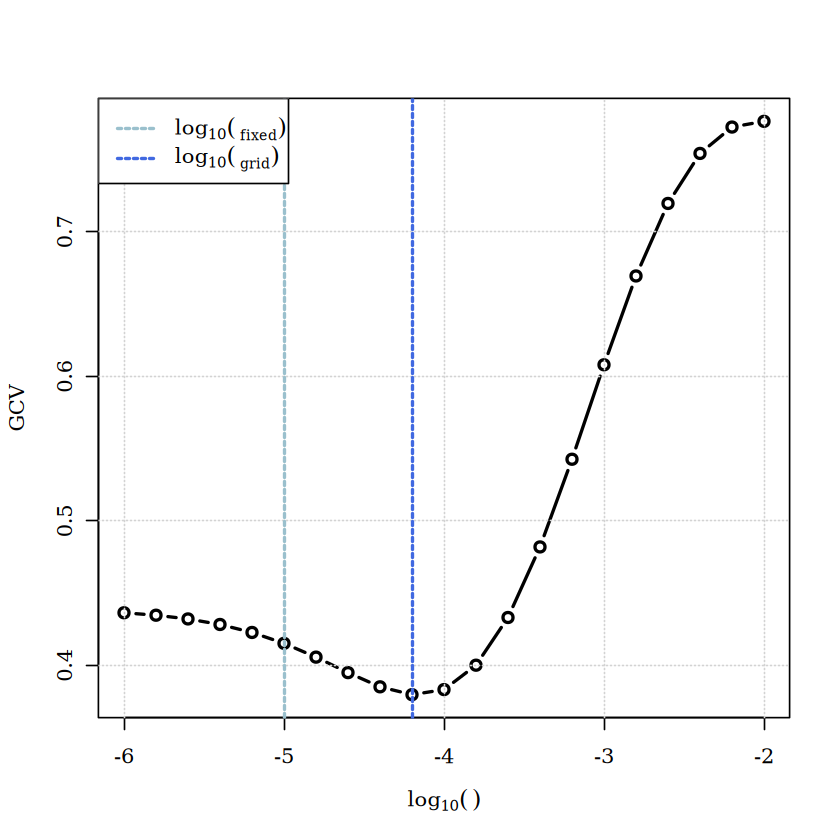

In [22]:
# Optimal value selected for the smoothing parameter
lambda_opt_grid <- fit_SST_iso_grid$optimum
cat("Optimal lambda value:", lambda_opt_grid)

# Plot of the GCV curve
par(family = "serif")
plot(x = log10(lambda_grid), y = fit_SST_iso_grid$values, type = "b",
     lwd = 2, xlab = TeX("$\\log_{10}(\\lambda)$"), ylab = "GCV")
grid()
abline(v = log10(lambda_fixed), lty = 2, lwd = 2, col = "lightblue3")
abline(v = log10(lambda_opt_grid), lty = 2, lwd = 2, col = "royalblue")
legend("topleft", lty = c(2, 2), lwd = c(2, 2), col = c("lightblue3", "royalblue"),
       legend = c(TeX("$\\log_{10}(\\lambda_{fixed})"),
                  TeX("$\\log_{10}(\\lambda_{grid})")))

<div style="text-align: center;">
Figure 6: GCV curve.
</div>

The GCV curve is convex with minimum realized at the optimal value selected by the method -- specifically, $0.0001\,.$

The regression model fit over the region of interest is displayed below (left). For qualitative comparison, the SST data from NASA satellite images is also displayed (right).

<iframe srcdoc="<!doctype html>
<html>
	<head>
 <meta charset="utf-8">
 <script title="htmlwidgets" src="..."></script>
<script title="jquery" src="..."></script>
<script title="leaflet" src="..."></script>
<link href="
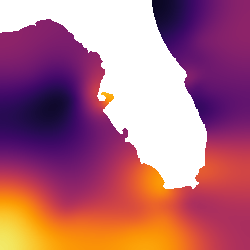
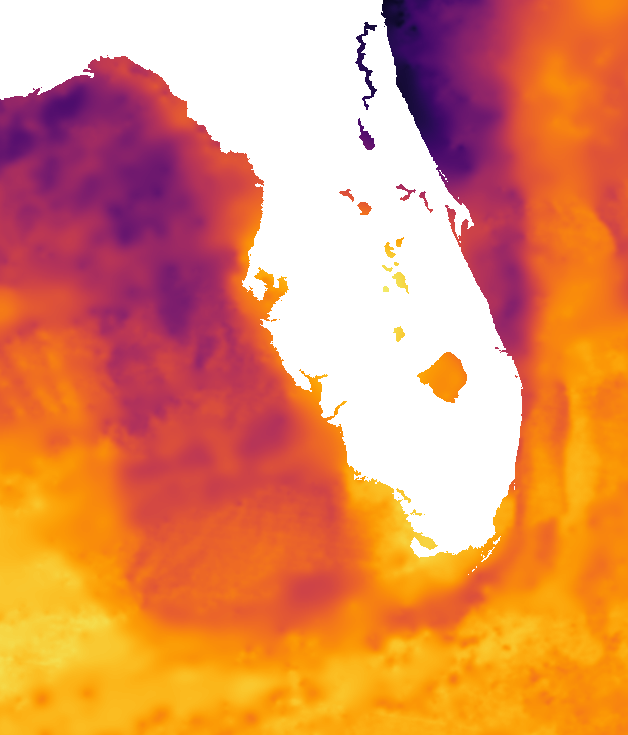

In [23]:
# Interactive plot
map1 <- mapview(f_SST_iso_grid, 
          crs = 4326, col.regions = inferno,
          na.color = "transparent", layer.name = "SST [°C]") +
        mapview(domain, 
          col.regions = "transparent", alpha.regions = 0,
          col = "black", lwd = 1.5, layer.name = "domain", legend = FALSE)

map2 <- mapview(SST - 273.15, 
          col.regions = inferno, na.color = "transparent",
          layer.name = "SST [°C]") +
        mapview(domain, 
          col.regions = "transparent", alpha.regions = 0,
          col = "black", lwd = 1.5, layer.name = "domain", legend = FALSE)

display_map(sync(map1, map2))

<div style="text-align: center;">
Figure 7: SST estimate provided by the isotropic `SR-PDE`$(I,\mathbf{0},0)$ without covariates and with $\lambda$ selected via GCV minimization through grid search (left); SST data from NASA satellite images (right). We recall that the latter are not used for estimation purposes; they are displayed here solely to allow comparison with the SST estimate computed by the proposed `SR-PDE` method, which instead is based on the 30 observations measured at the moored buoys.
</div>

The smoothing fit appears slightly more accurate than the previous fit compared to the satellite image data, although the anisotropy and non-stationarity behaviors could be captured by incorporating problem-specific knowledge derived from the physics of the underlying phenomenon.

### 4. SR-PDE model fitting for physics-informed smoothing (without covariates)

The phenomenon under study is heavily influenced by the *Gulf Stream*, a warm, swift, and non-stationary current in the Atlantic Ocean. The proposed `SR-PDE` method is well-suited for this type of data analysis, as it allows for the incorporation of physical knowledge into the modeling framework. In fact, the influence of the Gulf Stream on the spatial distribution of the considered oceanographic quantity can be properly captured by a *diffusion-transport PDE*. Thus, we apply **physics-informed smoothing** to the SST data, hereafter referred to as `SR-PDE`$(K,\mathbf{b},0)\,.$ This means that we consider:

- a **stationary and isotropic diffusion tensor**: $K = \eta I\,,$ where the diffusion intensity $\eta = 0.0218$ (assumed known; see, e.g., @bernardi2018modeling and @tomasetto2024modeling) and $I$ is the identity matrix;

- a **space-varying transport vector**: $\mathbf{b}(\mathbf{p})\,,$ which stores the Gulf Stream velocity at location $\mathbf{p}\,;$

- a **null reaction coefficient**: $c = 0\,;$

- a **null forcing term**: $u \equiv 0\,.$

We specify that the reaction coefficient can be set to zero, as the shrinkage effect is not relevant to the phenomenon under study. Moreover, the relatively small value of the diffusion intensity $\eta\,,$ compared to the values assumed by $\mathbf{b}(\mathbf{p})$ over the domain of interest, highlights that the transport term has a significant impact on the phenomenon under study, as it dominates the diffusion effect.

#### 4.1 PDE parameters

In this section we define the space-varying transport field $b$. Specifically, starting from the files `../../SRPDE_2D/Transport_x.tif` and `../../SRPDE_2D/Transport_y.tif`, we are able to define a function modeling the transport term at any arbitrary location $(x,y)$ using the `raster` [@hijmans2025raster] R package. These data -- specifically, the direction and intensity of the Gulf Stream around the Florida peninsula -- are provided by the [Ocean Surface Current Analysis Real-time (OSCAR)](https://podaac.jpl.nasa.gov/dataset/OSCAR%CB%99L4%CB%99OC%CB%99third-deg) dataset, with a 5-day resolution.

Below, we present an image illustrating the transport term over the Gulf of Mexico.

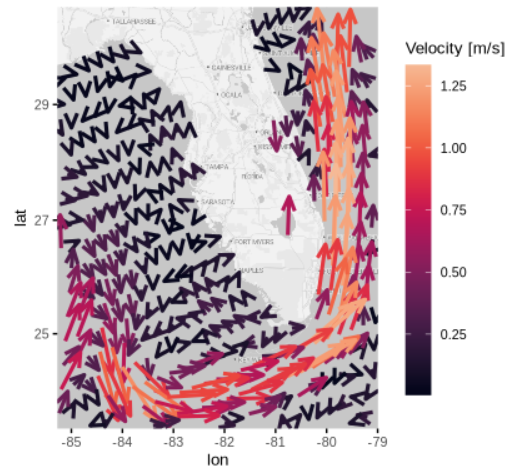

In [24]:
IRdisplay::display_png(
  file = "../../data/SRPDE_2D/transport_field.png",
  width = 513, height = 472
)

We can define the PDE parameters as either constant or standard R functions. The former is used to define the constant diffusion tensor, while the latter is used to encode non-constant coefficients, such as the Gulf stream:

In [25]:
## [PDE PARAMETERS]

# Diffusion tensor
K <- 0.0218 * diag(2)

# Load and cache both transport components
transport <- raster::stack(
  "../../data/SRPDE_2D/Transport_x.tif",
  "../../data/SRPDE_2D/Transport_y.tif"
)
transport_values <- raster::getValues(transport)

# Evaluate the advection field at an n-by-2 matrix of coordinates
b <- function(points) {
  cells <- raster::cellFromXY(transport, points)
  transport_values[cells, , drop = FALSE]
}

The reaction coefficient and the forcing term are not specified above, meaning that both are set to $0$ by default when initializing the `sr` model.

#### 4.2 Physics-informed smoothing with optimal smoothing parameter selected via Generalized Cross-Validation (GCV) minimization using grid search method

We perform the physics-informed `SR-PDE`$(K,\mathbf{b},0)$ method. Here, the optimal smoothing parameter is selected via GCV minimization using grid search method. This technique requires the stochastic computation of the degrees of freedom.

In [26]:
## [PHYSICS-INFORMED SMOOTHING WITH OPTIMAL SMOOTHING PARAMETER]
# Proposed values for the smoothing parameter
lambda_grid <- 10^seq(from = -6, to = -2, by = 0.2)

# Set up the finite element function (order 1)
f_SST_physics <- fe_function(mesh, type = "P1")

# Physics-informed smoothing model
model_SST_physics <- sr(formula = SST ~ f_SST_physics, data = florida, penalty = fe_elliptic(K = K, b = b))

# Physics-informed smoothing fit with grid search for GCV minimization
fit_SST_physics <- model_SST_physics$fit(
   calibrator = gcv(optimizer = grid_search(grid = lambda_grid))
)

We print the regression model outputs.

In [27]:
# Fitted values at mesh nodes
cat("Fitted values at mesh nodes:", head(f_SST_physics$coeff), "\n")

# Fitted values at locations
cat("Fitted values at locations:", head(model_SST_physics$fitted), "\n")

# Residuals at locations: response - fitted values
cat("Residuals\n")
SST_physics_residuals <- c(florida[["ocean"]]$SST - model_SST_physics$fitted)
summary(SST_physics_residuals)

# Optimal value selected for the smoothing parameter
lambda_opt_physics <- fit_SST_physics$optimum
cat("Optimal lambda value:", lambda_opt_physics)

Fitted values at mesh nodes: 25.76334 24.35116 27.50629 23.95429 23.94322 23.88667 
Fitted values at locations: 26.50095 25.69924 27.34873 25.58107 26.41394 26.93354 
Residuals


     Min.   1st Qu.    Median      Mean   3rd Qu.      Max. 
-0.153837 -0.015319  0.001909  0.000000  0.015671  0.103457 

Optimal lambda value: 0.01

The regression model fit over the region of interest is displayed below (bottom right). For qualitative comparison, the SST data from NASA satellite images is also displayed (top right).

<iframe srcdoc="<!doctype html>
<html>
	<head>
 <meta charset="utf-8">
 <script title="htmlwidgets" src="..."></script>
<script title="jquery" src="..."></script>
<script title="leaflet" src="..."></script>
<link href="
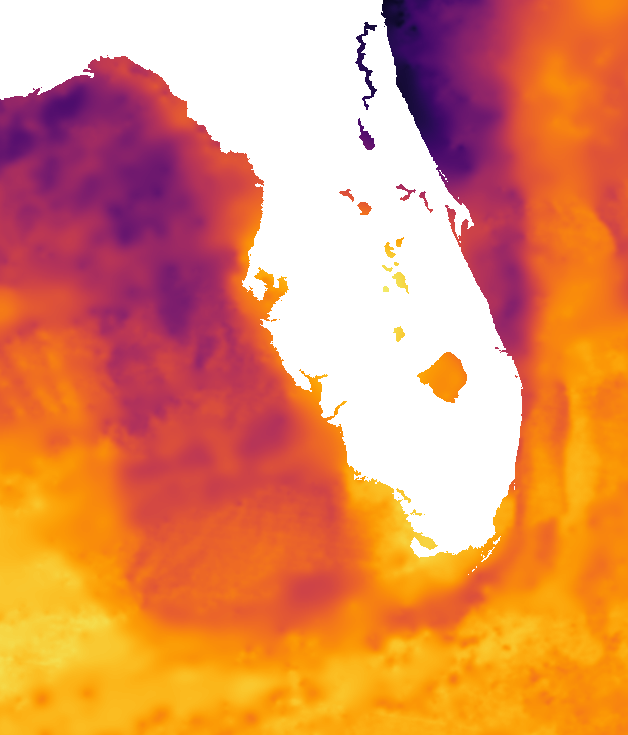
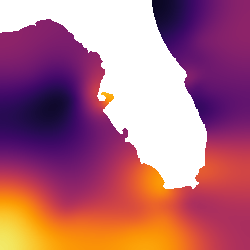
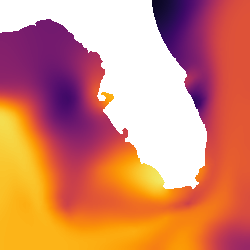

In [28]:
# Interactive plot
map1 <- mapview(florida[["ocean"]], 
          varnames = "SST", crs = 4326, layer.name = "SST [°C]",
          color_palettes = list("inferno"), na.color = "transparent") +
        mapview(domain, 
          col.regions = "transparent", alpha.regions = 0,
          col = "black", lwd = 1.5, layer.name = "domain", legend = FALSE)

map2 <- mapview(SST - 273.15, 
          col.regions = inferno, na.color = "transparent",
          layer.name = "SST [°C]") +
        mapview(domain, 
          col.regions = "transparent", alpha.regions = 0,
          col = "black", lwd = 1.5, layer.name = "domain", legend = FALSE)

map3 <- mapview(f_SST_iso_grid, 
          crs = 4326, col.regions = inferno,
          na.color = "transparent", layer.name = "SST [°C]") +
        mapview(domain, 
          col.regions = "transparent", alpha.regions = 0,
          col = "black", lwd = 1.5, layer.name = "domain", legend = FALSE)

map4 <- mapview(f_SST_physics, 
          crs = 4326, col.regions = inferno,
          na.color = "transparent", layer.name = "SST [°C]") +
        mapview(domain, 
          col.regions = "transparent", alpha.regions = 0,
          col = "black", lwd = 1.5, layer.name = "domain", legend = FALSE)

display_map(sync(map1, map2, map3, map4, ncol = 2))

<div style="text-align: center;">
Figure 9: SST data observed at 30 monitoring stations located in the Gulf of Mexico (top left); SST data from NASA satellite images (top right); SST estimate provided by the isotropic `SR-PDE`$(I,\mathbf{0},0)$ with $\lambda$ selected via GCV minimization using Netwon's method (bottom left); SST estimate provided by the physics-informed `SR-PDE`$(K,\mathbf{b},0)$ with $\lambda$ selected via GCV minimization using Netwon's method (bottom right). We recall that the latter are not used for estimation purposes; they are displayed here solely to allow comparison with the SST estimate computed by the proposed `SR-PDE` method, which instead is based on the 30 observations measured at the moored buoys.
</div>

This model fitting successfully captures the strongly anisotropic and non-stationary pattern of the SST. By leveraging problem-specific information -- specifically, the presence of the Gulf Stream -- the proposed `SR-PDE`$(K,\mathbf{b},0)$ method provides an accurate estimate of the spatial distribution of the quantity under study using only buoy measurements.

This insight is further supported by the boxplot of the residuals from the two methods, as shown below. For root mean square errors in cross-validation, refer to @tomasetto2024modeling.

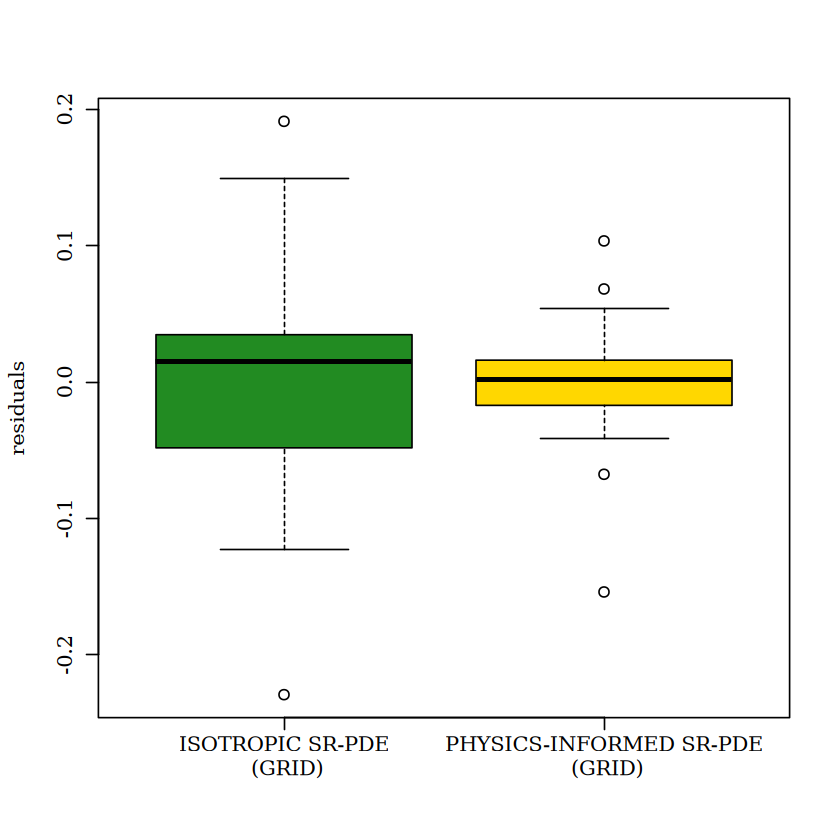

In [29]:
# Boxplot
par(family = "serif")
boxplot(SST_iso_grid_residuals, SST_physics_residuals, col = c("forestgreen", "gold"), ylab = "residuals")
axis(1, at = 1:2, line = 0.5, tick = FALSE, labels = c("ISOTROPIC SR-PDE\n (GRID)", "PHYSICS-INFORMED SR-PDE\n (GRID)"))

<div style="text-align: center;">
Figure 10: Boxplot of the residuals from the isotropic `SR-PDE`$(I,\mathbf{0},0)\,.$ with optimal $\lambda$ selected via GCV minimization using grid search method (first), and from the physics-informed `SR-PDE`$(K,\mathbf{b},0)$ (second).
</div>

### 5. SR-PDE model fitting for physics-informed smoothing (with covariates)

The `SR-PDE` model can incorporate **covariates** associated with the corresponding observed data values. We present an example based on the Dissolved Oxygen (DO) data, measured in $\mu\,\text{mol} / \text{kg}\,.$ and modeled using the Sea Surface Temperature (SST) as a covariate. The recorded values for SST and DO are shown in the interactive plot below.

In [30]:
# Interactive plot
map1 <- mapview(florida[["ocean"]], 
          varnames = "SST", crs = 4326,
          color_palettes = list("inferno"), na.color = "transparent",
          layer.name = "SST [°C]") +
        mapview(domain, 
          col.regions = "transparent", alpha.regions = 0,
          col = "black", lwd = 1.5, layer.name = "domain", legend = FALSE)

map2 <- mapview(florida[["ocean"]], 
          varnames = "DO", crs = 4326,
          color_palettes = list("viridis"), na.color = "transparent",
          layer.name = "DO") +
        mapview(domain, 
          col.regions = "transparent", alpha.regions = 0,
          col = "black", lwd = 1.5, layer.name = "domain", legend = FALSE)

display_map(sync(map1, map2))

<iframe srcdoc="<!doctype html>
<html>
	<head>
 <meta charset="utf-8">
 <script title="htmlwidgets" src="..."></script>
<script title="jquery" src="..."></script>
<script title="leaflet" src="..."></script>
<link href="

<div style="text-align: center;">
Figure 11: SST (left) and DO (right) observed at 30 monitoring stations located in the Gulf of Mexico, around the Florida peninsula, on April 1, 2020.
</div>

DO is strongly negatively correlated with SST, with a Pearson correlation coefficient of approximately −0.7125017.

In [31]:
cor(x = florida[["ocean"]]$SST, y = florida[["ocean"]]$DO, method = "pearson")

[1] -0.7125017

As water temperature rises, molecular motion increases, reducing the solubility of oxygen and leading to lower dissolved oxygen levels. Thus, we apply physics-informed smoothing to the DO data, including the SST data as a covariate into the modeling framework. This means that we consider:

- a **stationary and isotropic diffusion tensor**: $K = \eta I\,,$ where the diffusion intensity $\eta = 1.1341$ (assumed known; see, e.g., @tomasetto2024modeling) and $I$ is the identity matrix;

- a **space-varying transport vector**: $\mathbf{b}(\mathbf{p})\,,$ which stores the Gulf Stream velocity at location $\mathbf{p}\,;$

- a **null reaction coefficient**: $c = 0\,;$

- a **null forcing term**: $u \equiv 0\,.$

We modify the diffusion intensity value accordingly, while keeping all other PDE parameters unchanged from those used in the `SR-PDE`$(K,\mathbf{b},0)$ method applied to the SST data.

In [32]:
# Diffusion tensor
K <- 1.1341 * diag(2)

We perform the physics-informed `SR-PDE`$(K,\mathbf{b},0)$ method. Here, the optimal smoothing parameter is selected via GCV minimization using grid search method. This technique requires the stochastic computation of the degrees of freedom.

In [33]:
## [ISOTROPIC SMOOTHING WITH A COVARIATE AND OPTIMAL SMOOTHING PARAMETER]
# Set up the finite element function (order 1)
f_DO_physics <- fe_function(mesh, type = "P1")

# Physics-informed smoothing model
model_DO_physics <- sr(formula = DO ~ SST + f_DO_physics, data = florida, penalty = fe_elliptic(K = K, b = b))

# Physics-informed smoothing fit Grid Search method for GCV minimization
fit_DO_physics <- model_DO_physics$fit(
  calibrator = gcv(optimizer = grid_search(lambda_grid))
)

We print the regression model outputs.

In [34]:
# Fitted values at mesh nodes
cat("Fitted values at mesh nodes:", head(f_DO_physics$coeff), "\n")

# Fitted values at locations
cat("Fitted values at locations:", head(model_DO_physics$fitted), "\n")

# Residuals at locations: response - fitted values
cat("Residuals\n")
DO_physics_residuals <- c(florida[["ocean"]]$DO - model_DO_physics$fitted)
summary(DO_physics_residuals)

# Optimal value selected for the smoothing parameter
lambda_opt_physics <- fit_DO_physics$optimum
cat("Optimal lambda value:", lambda_opt_physics)

# Estimate of parameter beta
model_DO_physics$beta

Fitted values at mesh nodes: 221.255 204.987 205.0861 227.4906 227.6271 228.3258 
Fitted values at locations: 207.8663 208.5899 205.3264 208.7254 208.5862 207.8473 
Residuals


      Min.    1st Qu.     Median       Mean    3rd Qu.       Max. 
-0.0159428 -0.0032196  0.0002942  0.0000000  0.0035508  0.0139123 

Optimal lambda value: 1e-06

[1] 0.04724586

The regression model fit over the region of interest is instead displayed below.

<iframe srcdoc="<!doctype html>
<html>
	<head>
 <meta charset="utf-8">
 <script title="htmlwidgets" src="..."></script>
<script title="jquery" src="..."></script>
<script title="leaflet" src="..."></script>
<link href="
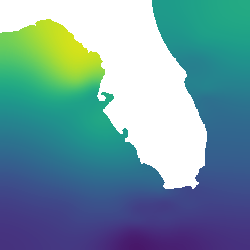

In [35]:
# Interactive plot
map1 <- mapview(f_DO_physics, 
          crs = 4326, col.regions = viridis,
          na.color = "transparent", layer.name = "DO") +
        mapview(domain, 
          col.regions = "transparent", alpha.regions = 0,
          col = "black", lwd = 1.5, layer.name = "domain", legend = FALSE)

map2 <- mapview(florida[["ocean"]], 
          varnames = "DO", crs = 4326,
          color_palettes = list("viridis"), na.color = "transparent",
          layer.name = "DO") +
        mapview(domain, 
          col.regions = "transparent", alpha.regions = 0,
          col = "black", lwd = 1.5, layer.name = "domain", legend = FALSE)

display_map(sync(map1, map2))

<div style="text-align: center;">
Figure 12: SST estimate provided by the physics-informed `SR-PDE`$(K,\mathbf{b},0)$ with optimal $\lambda$ selected via GCV minimization using Netwon's method and using SST as a covariate (left); DO data observed at 30 monitoring stations located in the Gulf of Mexico (right).
</div>

This model fitting successfully proves to capture the strongly anisotropic and non-stationary pattern exhibited by the DO data, leveraging both the physics of the underlying phenomenon and information from the SST data.

## References

<div id="refs" class="references csl-bib-body hanging-indent"
data-entry-spacing="0" data-line-spacing="2" role="list">
<div id="ref-appelhans2025mapview" class="csl-entry" role="listitem">
Appelhans, T., Detsch, F., Reudenbach, C., &amp; Woellauer, S. (2023).
<em>Mapview: <span>I</span>nteractive viewing of spatial data in
<span>R</span></em>. url: <a
href="https://CRAN.R-project.org/package=mapview"
class="uri">https://CRAN.R-project.org/package=mapview</a>.
</div>
<div id="ref-arnone2019modeling" class="csl-entry" role="listitem">
Arnone, E., Azzimonti, L., Nobile, F., &amp; Sangalli, L. M. (2019).
Modeling spatially dependent functional data via regression with
differential regularization. <em>Journal of Multivariate Analysis</em>,
<em>170</em>, 275–295. <a
href="https://doi.org/10.1016/j.jmva.2018.09.006">https://doi.org/10.1016/j.jmva.2018.09.006</a>
</div>
<div id="ref-arnone2023analyzing" class="csl-entry" role="listitem">
Arnone, E., Negri, L., Panzica, F., &amp; Sangalli, L. M. (2023).
Analyzing data in complicated 3D domains: Smoothing, semiparametric
regression, and functional principal component analysis.
<em>Biometrics</em>, <em>79</em>(4), 3510–3521. <a
href="https://doi.org/10.1111/biom.13845">https://doi.org/10.1111/biom.13845</a>
</div>
<div id="ref-azzimonti2014mixed" class="csl-entry" role="listitem">
Azzimonti, L., Nobile, F., Sangalli, L. M., &amp; Secchi, P. (2014).
Mixed finite elements for spatial regression with PDE penalization.
<em>SIAM/ASA Journal on Uncertainty Quantification</em>, <em>2</em>(1),
305–335. <a
href="https://doi.org/10.1137/130925426">https://doi.org/10.1137/130925426</a>
</div>
<div id="ref-azzimonti2015blood" class="csl-entry" role="listitem">
Azzimonti, L., Sangalli, L. M., Secchi, P., Domanin, M., &amp; Nobile,
F. (2015). Blood flow velocity field estimation via spatial regression
with PDE penalization. <em>Journal of the American Statistical
Association</em>, <em>110</em>(511), 1057–1071. <a
href="https://doi.org/10.1080/01621459.2014.946036">https://doi.org/10.1080/01621459.2014.946036</a>
</div>
<div id="ref-bernardi2018modeling" class="csl-entry" role="listitem">
Bernardi, M. S., Carey, M., Ramsay, J. O., &amp; Sangalli, L. M. (2018).
Modeling spatial anisotropy via regression with partial differential
regularization. <em>Journal of Multivariate Analysis</em>, <em>167</em>,
15–30. <a
href="https://doi.org/10.1016/j.jmva.2018.03.014">https://doi.org/10.1016/j.jmva.2018.03.014</a>
</div>
<div id="ref-ettinger2016spatial" class="csl-entry" role="listitem">
Ettinger, B., Perotto, S., &amp; Sangalli, L. M. (2016). Spatial
regression models over two-dimensional manifolds. <em>Biometrika</em>,
<em>103</em>(1), 71–88.
</div>
<div id="ref-hijmans2025raster" class="csl-entry" role="listitem">
Hijmans, R. J. (2025). <em>Raster: <span>G</span>eographic data analysis
and modeling</em>. url: <a
href="https://CRAN.R-project.org/package=raster"
class="uri">https://CRAN.R-project.org/package=raster</a>.
</div>
<div id="ref-lindgren2025fmesher" class="csl-entry" role="listitem">
Lindgren, F. (2025). <em>Fmesher: <span>T</span>riangle meshes and
related geometry tools</em>. url: <a
href="https://CRAN.R-project.org/package=fmesher"
class="uri">https://CRAN.R-project.org/package=fmesher</a>.
</div>
<div id="ref-palummo2026fdapde" class="csl-entry" role="listitem">
Palummo, A., Clemente, A., Sangalli, E., Arnone, Formaggia, L., &amp;
Maria, L. (2025). <em>fdaPDE: <span>P</span>hysics-informed statistical
learning</em>. url: <a href="https://github.com/fdaPDE/fdaPDE-R"
class="uri">https://github.com/fdaPDE/fdaPDE-R</a>.
</div>
<div id="ref-pebesma2025sf" class="csl-entry" role="listitem">
Pebesma, E. (2025). <em>Sf: <span>S</span>imple <span>F</span>eatures
for <span>R</span></em>. url: <a
href="https://CRAN.R-project.org/package=sf"
class="uri">https://CRAN.R-project.org/package=sf</a>.
</div>
<div id="ref-sangalli2021spatial" class="csl-entry" role="listitem">
Sangalli, L. M. (2021). Spatial regression with partial differential
equation regularisation. <em>International Statistical Review</em>,
<em>89</em>(3), 505–531. <a
href="https://doi.org/10.1111/insr.12444">https://doi.org/10.1111/insr.12444</a>
</div>
<div id="ref-sangalli2013spatial" class="csl-entry" role="listitem">
Sangalli, L. M., Ramsay, J. O., &amp; Ramsay, T. O. (2013). Spatial
spline regression models. <em>Journal of the Royal Statistical Society
Series B: Statistical Methodology</em>, <em>75</em>(4), 681–703. <a
href="https://doi.org/10.1111/rssb.12009">https://doi.org/10.1111/rssb.12009</a>
</div>
<div id="ref-shewchuk2025RTriangle" class="csl-entry" role="listitem">
Shewchuk, J. R., &amp; Sterratt, D. C. (2025). <em>RTriangle - a
2<span>D</span> quality mesh generator and <span>D</span>elaunay
triangulator</em>. url: <a
href="https://CRAN.R-project.org/package=RTriangle"
class="uri">https://CRAN.R-project.org/package=RTriangle</a>.
</div>
<div id="ref-teucher2025rmapshaper" class="csl-entry" role="listitem">
Teucher, A., Russell, K., &amp; Bloch, M. (2023). <em>Rmapshaper:
<span>C</span>lient for ’mapshaper’ for ’geospatial’ operations</em>.
url: <a href="https://CRAN.R-project.org/package=rmapshaper"
class="uri">https://CRAN.R-project.org/package=rmapshaper</a>.
</div>
<div id="ref-tomasetto2024modeling" class="csl-entry" role="listitem">
Tomasetto, M., Arnone, E., &amp; Sangalli, L. M. (2024). Modeling
anisotropy and non-stationarity through physics-informed spatial
regression. <em>Environmetrics</em>, <em>35</em>(8). <a
href="https://doi.org/10.1002/env.2889">https://doi.org/10.1002/env.2889</a>
</div>
<div id="ref-walker2025tigris" class="csl-entry" role="listitem">
Walker, K. (2025). <em>Tigris: <span>L</span>oad census TIGER/line
shapefiles</em>. url: <a
href="https://CRAN.R-project.org/package=tigris"
class="uri">https://CRAN.R-project.org/package=tigris</a>.
</div>
</div>